# Tasks - Lab 2


## Task 3.1


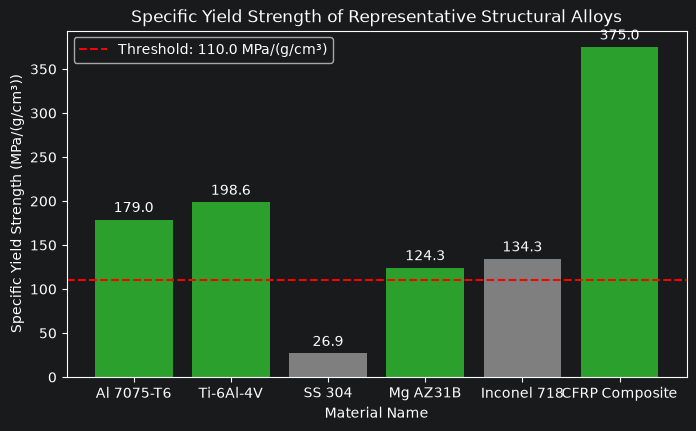

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# INPUT DATA: REPRESENTATIVE STRUCTURAL ALLOYS
# ==============================================================================
alloys_data = {
    "material_name": [
        "Al 7075-T6",
        "Ti-6Al-4V",
        "SS 304",
        "Mg AZ31B",
        "Inconel 718",
        "CFRP Composite",
    ],
    "density_g_cm3": [2.81, 4.43, 8.00, 1.77, 8.19, 1.60],
    "yield_strength_mpa": [503.0, 880.0, 215.0, 220.0, 1100.0, 600.0],
    "youngs_modulus_gpa": [71.7, 113.8, 193.0, 45.0, 205.0, 140.0],
}
df_alloys = pd.DataFrame(alloys_data)

# ==============================================================================
# TODO 1: CONVERT DATAFRAME TO NUMPY ARRAYS
# Extract density, yield strength, and material names as independent 1D NumPy arrays
# ==============================================================================
density = df_alloys["density_g_cm3"].to_numpy()
yield_strength = df_alloys["yield_strength_mpa"].to_numpy()
material_names = df_alloys["material_name"].to_numpy()

# ==============================================================================
# TODO 2: VECTORIZED CALCULATION OF SPECIFIC METRICS
# Compute specific yield strength: specific_strength = yield_strength / density
# ==============================================================================
specific_strength = yield_strength / density

# ==============================================================================
# TODO 3: BOOLEAN SCREENING MASK
# Find materials with: (density <= 4.6) AND (specific_strength >= 110.0)
# ==============================================================================
qualifying_mask = (density <= 4.6) & (specific_strength >= 110.0)
qualifying_materials = material_names[qualifying_mask]


# ==============================================================================
# TODO 4: MATPLOTLIB BAR PLOT (OBJECT-ORIENTED)
# 1. Create fig, ax with figsize=(8, 4.5)
# 2. Assign dynamic colors: e.g. '#2ca02c' (green) for qualifying, '#7f7f7f' (gray) for others
# 3. Plot bars using ax.bar()
# 4. Add threshold line at 110.0 with ax.axhline()
# 5. Add titles, labels with units, and value labels via ax.bar_label()
# ==============================================================================
fig, ax = plt.subplots(
    figsize=(8, 4.5),
)

ax.bar(
    material_names,
    specific_strength,
    color=["#2ca02c" if q else "#7f7f7f" for q in qualifying_mask],
)
ax.axhline(
    y=110.0,
    color="red",
    linestyle="--",
    label="Threshold: 110.0 MPa/(g/cm³)",
)
ax.set_title("Specific Yield Strength of Representative Structural Alloys")
ax.set_xlabel("Material Name")
ax.set_ylabel("Specific Yield Strength (MPa/(g/cm³))")
ax.bar_label(
    ax.containers[0],
    fmt="%.1f",
    padding=3,
)
ax.legend()

plt.show()

## Task 3.2

#### Tasks to Complete:
1. Generate an array of 150 temperature values $T$ from $600\ \mathrm{K}$ to $1300\ \mathrm{K}$ using `np.linspace()`.
2. Vectorize the computation of $D_\alpha(T)$ and $D_\gamma(T)$ using `np.exp()`.
3. Locate the temperature $T_{\text{cross}}$ where the two diffusion curves intersect (where $\vert{}D_\alpha - D_\gamma\vert{}$ is minimized) using `np.argmin()`.
4. Plot both diffusion profiles on a semi-logarithmic scale (`ax.semilogy` or `ax.set_yscale('log')`):
   * Add markers and annotations pinpointing the crossover point.
   * Provide proper physical axis labels with exponents and units.

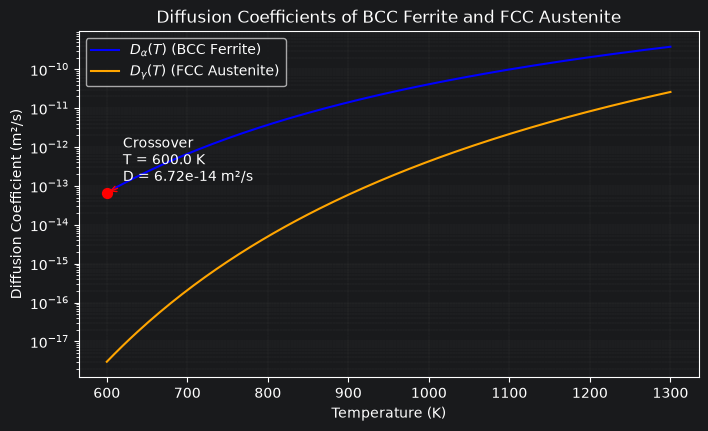

In [17]:
import matplotlib.pyplot as plt

# ==============================================================================
# PHYSICAL CONSTANTS & ARRHENIUS PARAMETERS
# ==============================================================================
R_GAS = 8.314  # Gas constant [J / (mol * K)]

# Alpha-Fe (BCC Ferrite) parameters
D0_ALPHA = 6.2e-7  # Pre-exponential factor [m²/s]
Q_ALPHA = 80_000.0  # Activation energy [J/mol]

# Gamma-Fe (FCC Austenite) parameters
D0_GAMMA = 2.3e-5  # Pre-exponential factor [m²/s]
Q_GAMMA = 148_000.0  # Activation energy [J/mol]

# ==============================================================================
# TODO 1: GENERATE TEMPERATURE GRID VIA np.linspace
# Create 150 points between 600 K and 1300 K
# ==============================================================================
T_MIN = 600.0  # Minimum temperature [K]
T_MAX = 1300.0  # Maximum temperature [K]

temperatures_K = np.linspace(T_MIN, T_MAX, 150)

# ==============================================================================
# TODO 2: VECTORIZED ARRHENIUS DIFFUSION COEFFICIENTS
# Compute D_alpha and D_gamma using np.exp
# ==============================================================================
D_alpha = D0_ALPHA * np.exp(-Q_ALPHA / (R_GAS * temperatures_K))
D_gamma = D0_GAMMA * np.exp(-Q_GAMMA / (R_GAS * temperatures_K))

# ==============================================================================
# TODO 3: LOCATE CROSSOVER TEMPERATURE
# Use np.abs and np.argmin to find the index where D_alpha ≈ D_gamma
# ==============================================================================
crossover_idx = np.argmin(np.abs(D_alpha - D_gamma))
T_cross = temperatures_K[crossover_idx]
D_cross = D_alpha[crossover_idx]  # or D_gamma for example ;)

# ==============================================================================
# TODO 4: SCIENTIFIC LINE PLOT (SEMI-LOGARITHMIC)
# 1. Initialize fig, ax
# 2. Plot D_alpha and D_gamma curves
# 3. Set y-axis to logarithmic scale: ax.set_yscale("log")
# 4. Highlight crossover point with ax.scatter() and ax.annotate()
# 5. Add axis labels, units, grid, and legend
# ==============================================================================
fig, ax = plt.subplots(
    figsize=(8, 4.5),
)
ax.plot(
    temperatures_K,
    D_alpha,
    label=r"$D_\alpha(T)$ (BCC Ferrite)",
    color="blue",
)
ax.plot(
    temperatures_K,
    D_gamma,
    label=r"$D_\gamma(T)$ (FCC Austenite)",
    color="orange",
)

ax.set_yscale("log")
ax.scatter(
    T_cross,
    D_cross,
    color="red",
    s=50,
    zorder=5,
)
ax.annotate(
    f"Crossover\nT = {T_cross:.1f} K\nD = {D_cross:.2e} m²/s",
    xy=(T_cross, D_cross),
    xytext=(T_cross + 20, D_cross * 2),
    arrowprops=dict(arrowstyle="->", color="red"),
    fontsize=10,
)


ax.set_title("Diffusion Coefficients of BCC Ferrite and FCC Austenite")
ax.set_xlabel("Temperature (K)")
ax.set_ylabel("Diffusion Coefficient (m²/s)")
ax.grid(True, which="both", linestyle="--", linewidth=0.1)
ax.legend()

plt.show()

## Task 3.3

#### Tasks to Complete:
1. Load the noble gas parameter table (`Argon` vs. `Krypton`) given as a `pd.DataFrame` and convert it into a NumPy array.
2. Generate an interatomic separation vector $r$ from $3.1\ \mathrm{\mathring{A}}$ to $7.0\ \mathrm{\mathring{A}}$ (200 points) using `np.linspace()`.
3. Vectorize the computation of $V(r)$ for Argon ($\varepsilon = 0.0104\ \mathrm{eV}$, $\sigma = 3.40\ \mathrm{\mathring{A}}$) and Krypton ($\varepsilon = 0.0140\ \mathrm{eV}$, $\sigma = 3.65\ \mathrm{\mathring{A}}$).
4. Numerically locate the equilibrium distance $r_0$ and potential minimum using `np.argmin()`, and verify against the theoretical analytical value.
5. Create an **Energy vs. Separation Plot**:
   * Plot potential curves $V(r)$ for both noble gases.
   * Mark the energy minimum for each curve with `ax.scatter()`.
   * Add a horizontal zero-energy baseline (`ax.axhline(0)`).
   * Restrict the Y-axis limits (`ax.set_ylim(-0.018, 0.025)`) to prevent the repulsive $r^{-12}$ core from dominating the scale.

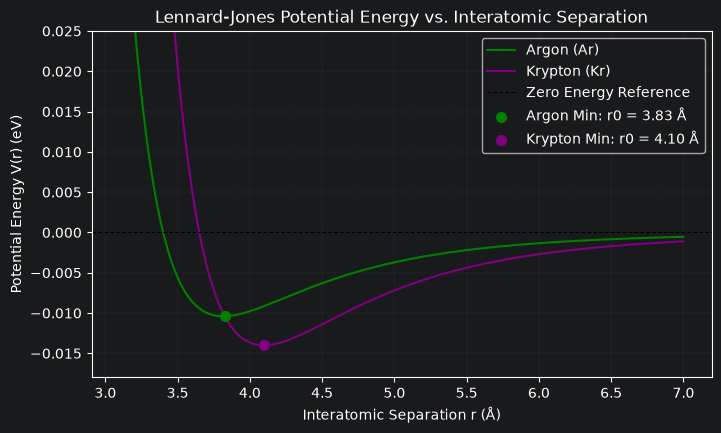

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==============================================================================
# INPUT DATA: LENNARD-JONES PARAMETERS (PANDAS DATAFRAME)
# ==============================================================================
lj_params_df = pd.DataFrame(
    {
        "species": ["Argon (Ar)", "Krypton (Kr)"],
        "epsilon_eV": [0.0104, 0.0140],  # Well depth [eV]
        "sigma_angstrom": [3.40, 3.65],  # Zero-potential distance [Å]
    }
)

# ==============================================================================
# TODO 1: EXTRACT PARAMETERS TO NUMPY
# ==============================================================================
eps_Ar, eps_Kr = lj_params_df["epsilon_eV"].to_numpy()
sig_Ar, sig_Kr = lj_params_df["sigma_angstrom"].to_numpy()

# ==============================================================================
# TODO 2: GENERATE RADIAL COORDINATE GRID
# Create 200 points from 3.1 to 7.0 Ångströms using np.linspace
# ==============================================================================
A_MIN = 3.1  # Minimum separation [Å]
A_MAX = 7.0  # Maximum separation [Å]

r_angstrom = np.linspace(A_MIN, A_MAX, 200)

# ==============================================================================
# TODO 3: VECTORIZED LENNARD-JONES POTENTIAL CALCULATION
# Formula: V(r) = 4 * eps * [ (sig/r)**12 - (sig/r)**6 ]
# ==============================================================================
V_argon = 4 * eps_Ar * ((sig_Ar / r_angstrom) ** 12 - (sig_Ar / r_angstrom) ** 6)
V_krypton = 4 * eps_Kr * ((sig_Kr / r_angstrom) ** 12 - (sig_Kr / r_angstrom) ** 6)

# ==============================================================================
# TODO 4: NUMERICAL EXTRACT OF EQUILIBRIUM SEPARATION (np.argmin)
# ==============================================================================
min_idx_Ar = np.argmin(V_argon)
r0_Ar_numerical = r_angstrom[min_idx_Ar]
r0_Ar_analytical = (2.0 ** (1.0 / 6.0)) * sig_Ar

# ==============================================================================
# TODO 5: ENERGY PROFILE VISUALIZATION
# 1. Initialize fig, ax
# 2. Plot V_argon and V_krypton curves
# 3. Add zero-energy reference line with ax.axhline(0.0)
# 4. Highlight minima with ax.scatter()
# 5. Restrict Y-limits via ax.set_ylim(-0.018, 0.025) to clearly resolve the well
# ==============================================================================
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(
    r_angstrom,
    V_argon,
    label="Argon (Ar)",
    color="green",  # GT Reference xd
)
ax.plot(
    r_angstrom,
    V_krypton,
    label="Krypton (Kr)",
    color="purple",
)

ax.axhline(
    y=0.0,
    color="black",
    linestyle="--",
    linewidth=0.8,
    label="Zero Energy Reference",
)

ax.scatter(
    r0_Ar_numerical,
    V_argon[min_idx_Ar],
    color="green",
    s=50,
    zorder=5,
    label=f"Argon Min: r0 = {r0_Ar_numerical:.2f} Å",
)

ax.scatter(
    (2.0 ** (1.0 / 6.0)) * sig_Kr,
    V_krypton[np.argmin(V_krypton)],
    color="purple",
    s=50,
    zorder=5,
    label=f"Krypton Min: r0 = {(2.0 ** (1.0 / 6.0)) * sig_Kr:.2f} Å",
)

ax.set_title("Lennard-Jones Potential Energy vs. Interatomic Separation")
ax.set_xlabel("Interatomic Separation r (Å)")
ax.set_ylabel("Potential Energy V(r) (eV)")
ax.set_ylim(-0.018, 0.025)
ax.grid(True, which="both", linestyle="--", linewidth=0.1)
ax.legend()


plt.show()